<a href="https://colab.research.google.com/github/avtonomov-petr/cliometric-spectral-audit/blob/main/cliometric_spectral_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import glob
import os
import warnings
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import eigh, svd
from scipy.spatial.distance import pdist, squareform
from scipy.stats import levene, mannwhitneyu

warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)
plt.rcParams["figure.dpi"] = 140
plt.rcParams["savefig.bbox"] = "tight"


def participation_ratio(vec):
  """Normalized Participation Ratio PR in [1/N, 1]."""
  v = np.asarray(vec, dtype=float)
  p = (v**2) / np.sum(v**2)
  return float(1.0 / (len(v) * np.sum(p**2)))


def run_first_echelon_bypass(X_raw, labels):
  """First Echelon (Bypass): Z-score standardization + thin SVD."""
  X_z = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)
  U, S, Vt = svd(X_z, full_matrices=False)
  energy = (S**2) / np.sum(S**2)
  weights_v1 = Vt[0, :] ** 2
  order = np.argsort(weights_v1)[::-1]
  top_idx = int(order.item(0))
  return {
      "U": U,
      "S": S,
      "Vt": Vt,
      "energy_1": float(energy.item(0)),
      "pr_u1": participation_ratio(U[:, 0]),
      "pr_v1": participation_ratio(Vt[0, :]),
      "weights_v1": weights_v1,
      "order": order,
      "top_label": labels[top_idx],
      "top_share": float(weights_v1[top_idx]),
  }


def bootstrap_pr(X_raw, n_iter=300, frac=0.8, seed=42):
  """Bootstrap stability check for PR(u1) and PR(v1) (subsampling without replacement)."""
  rng = np.random.default_rng(seed)
  n_samples = len(X_raw)
  sub_size = int(frac * n_samples)
  pr_u, pr_v = [], []
  for _ in range(n_iter):
    idx = np.sort(rng.choice(n_samples, size=sub_size, replace=False))
    X_sub = X_raw[idx]
    X_z = (X_sub - X_sub.mean(axis=0)) / X_sub.std(axis=0)
    U_b, _, Vt_b = svd(X_z, full_matrices=False)
    pr_u.append(participation_ratio(U_b[:, 0]))
    pr_v.append(participation_ratio(Vt_b[0, :]))
  return {
      "u1_ci": (
          float(np.percentile(pr_u, 2.5)),
          float(np.percentile(pr_u, 97.5)),
      ),
      "v1_ci": (
          float(np.percentile(pr_v, 2.5)),
          float(np.percentile(pr_v, 97.5)),
      ),
  }


def build_lsym_and_fiedler(X_mat, k_nn=6):
  """Second Echelon: symmetric k-NN similarity graph and normalized Laplacian L_sym."""
  dist = squareform(pdist(X_mat, metric="euclidean"))
  sigma = float(np.median(dist[dist > 0]))
  W = np.exp(-(dist**2) / (2.0 * sigma**2))
  np.fill_diagonal(W, 0.0)
  n_nodes = len(W)
  k_eff = min(k_nn, n_nodes - 2)
  for i in range(n_nodes):
    W[i, np.argsort(W[i])[::-1][k_eff:]] = 0.0
  W = 0.5 * (W + W.T)
  deg = np.sum(W, axis=1)
  d_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(deg, 1e-12)))
  L_sym = np.eye(n_nodes) - d_inv_sqrt @ W @ d_inv_sqrt
  evals, evecs = eigh(L_sym)
  gap = float(evals.item(1) - evals.item(0))
  return W, evals, evecs, gap


def leave_one_out_scan(
    X_diff_z, years_diff, labels, scan_range, test_type="mean", k_nn=6
):
  """Blind change-point scan + column-wise Leave-One-Out (LOO) stability test."""
  _, _, evecs_base, _ = build_lsym_and_fiedler(X_diff_z, k_nn=k_nn)
  u2_base = evecs_base[:, 1]

  p_scan = []
  for y in scan_range:
    idx = int(np.searchsorted(years_diff, y))
    if test_type == "mean":
      _, p = mannwhitneyu(u2_base[:idx], u2_base[idx:])
    else:
      _, p = levene(u2_base[:idx], u2_base[idx:], center="median")
    p_scan.append(float(p))

  best_yr = int(scan_range[int(np.argmin(p_scan))])
  min_p = float(np.min(p_scan))
  idx_best = int(np.searchsorted(years_diff, best_yr))

  loo_results = {}
  for j, name in enumerate(labels):
    keep = [i for i in range(len(labels)) if i != j]
    _, _, evecs_sub, _ = build_lsym_and_fiedler(X_diff_z[:, keep], k_nn=k_nn)
    u2_sub = evecs_sub[:, 1]
    if test_type == "mean":
      _, p_sub = mannwhitneyu(u2_sub[:idx_best], u2_sub[idx_best:])
    else:
      _, p_sub = levene(u2_sub[:idx_best], u2_sub[idx_best:], center="median")
    loo_results[name] = float(p_sub)

  return best_yr, min_p, p_scan, loo_results, u2_base


print("Protocol core initialized. Directory 'figures/' is ready.")


Protocol core initialized. Directory 'figures/' is ready.


=== CASE 1: MADDISON 1820–1950 (131 years x 12 countries) ===
Mode 1 Energy: 89.57%
PR(u1) = 0.485 (0.43408143718821407, 0.5341339792936044) | PR(v1) = 0.998 (0.9967402203892355, 0.9980692942315106)

Blind change-point detector (L_sym): min p = 1.60e-06 in 1891
  Sensitivity upon excluding 'Peru': p = 6.52e-01
  Sensitivity upon excluding 'Sweden': p = 2.48e-02
  Sensitivity upon excluding 'Australia': p = 5.58e-03


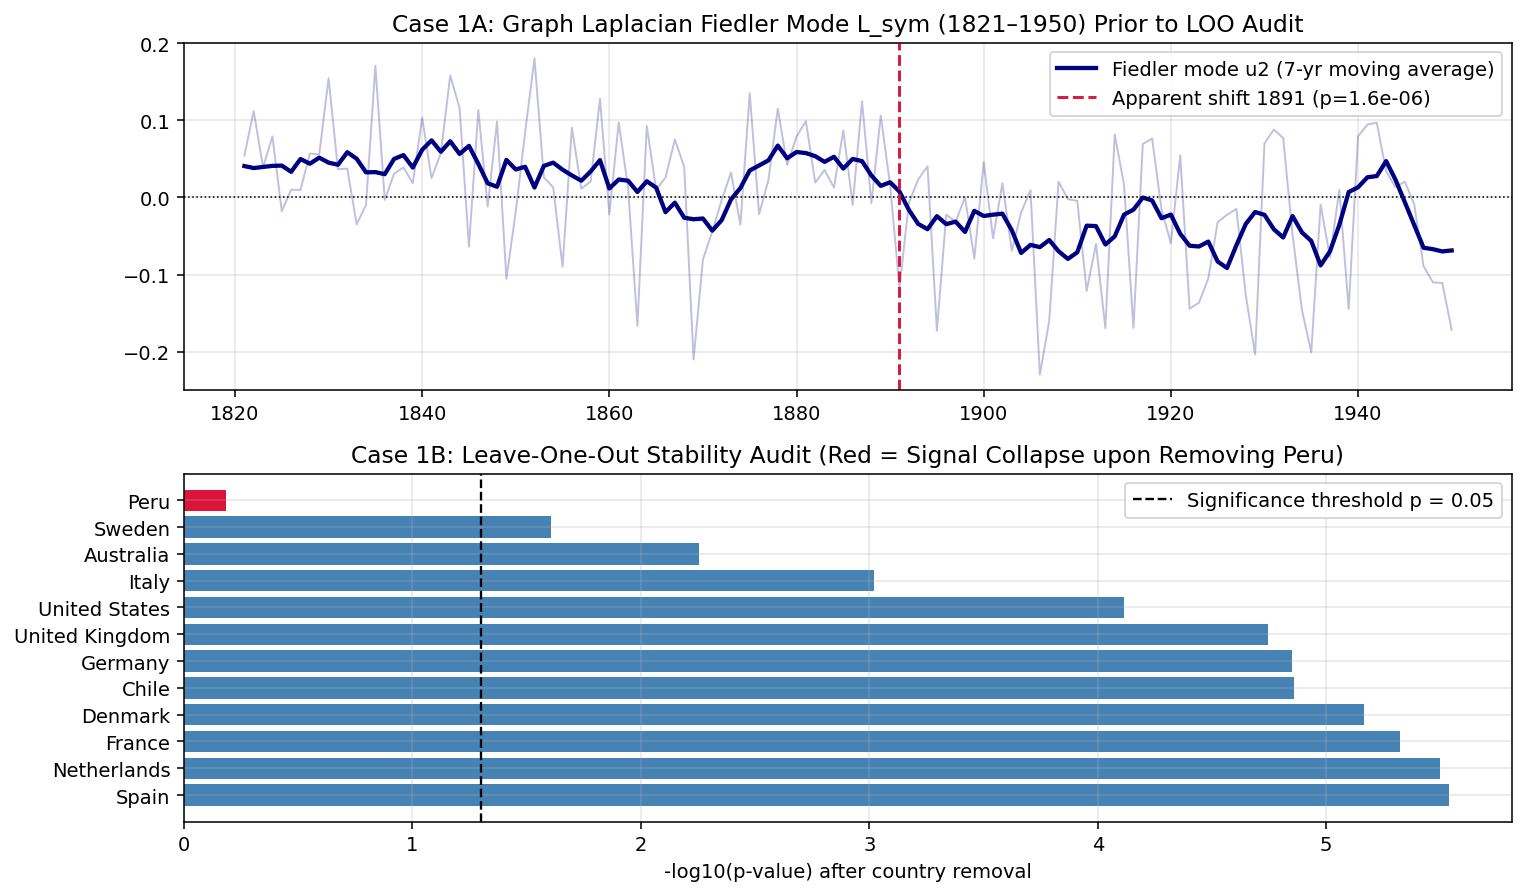

In [ ]:
xlsx_files = [f for f in os.listdir(".") if f.endswith(".xlsx")]
if not xlsx_files:
  raise FileNotFoundError(
      "Please upload 'mpd2023_web.xlsx' to the Colab Files panel!"
  )

mpd_file = xlsx_files.pop(0)
df_mpd = pd.read_excel(mpd_file, sheet_name="Full data")
df_piv = df_mpd.pivot(index="year", columns="country", values="gdppc")

# 1. Subsample 1820-1950
df_ind = df_piv.loc[1820:1950].dropna(axis=1)
countries_ind = df_ind.columns.tolist()
X_ind = df_ind.values.astype(float)
yrs_ind = df_ind.index.values

res1_ind = run_first_echelon_bypass(X_ind, countries_ind)
boot_ind = bootstrap_pr(X_ind, n_iter=300)

print(
    f"=== CASE 1: MADDISON 1820–1950 ({len(yrs_ind)} years x"
    f" {len(countries_ind)} countries) ==="
)
print(f"Mode 1 Energy: {res1_ind['energy_1']:.2%}")
print(
    f"PR(u1) = {res1_ind['pr_u1']:.3f} {boot_ind['u1_ci']} | PR(v1) ="
    f" {res1_ind['pr_v1']:.3f} {boot_ind['v1_ci']}"
)

# 2. Second Echelon (L_sym on log-differences) + blind change-point scan + LOO
X_diff_ind = np.diff(np.log(X_ind), axis=0)
X_diff_ind_z = (X_diff_ind - X_diff_ind.mean(axis=0)) / X_diff_ind.std(axis=0)
yrs_diff_ind = yrs_ind[1:]

best_yr, min_p, p_scan, loo_ind, u2_ind = leave_one_out_scan(
    X_diff_ind_z,
    yrs_diff_ind,
    countries_ind,
    np.arange(1845, 1930),
    test_type="mean",
    k_nn=6,
)
print(
    f"\nBlind change-point detector (L_sym): min p = {min_p:.2e} in {best_yr}"
)
for k, v in sorted(loo_ind.items(), key=lambda x: -x[1])[:3]:
  print(f"  Sensitivity upon excluding '{k}': p = {v:.2e}")

# 3. Plot and save Case 1 figure
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5))
u2_smooth = np.convolve(u2_ind, np.ones(7) / 7, mode="same")
ax1.plot(yrs_diff_ind, u2_ind, color="navy", alpha=0.25, lw=1)
ax1.plot(
    yrs_diff_ind,
    u2_smooth,
    color="navy",
    lw=2.2,
    label="Fiedler mode u2 (7-yr moving average)",
)
ax1.axhline(0, color="black", ls=":", lw=0.8)
ax1.axvline(
    best_yr,
    color="crimson",
    ls="--",
    lw=1.5,
    label=f"Apparent shift {best_yr} (p={min_p:.1e})",
)
ax1.set_title(
    "Case 1A: Graph Laplacian Fiedler Mode L_sym (1821–1950) Prior to LOO Audit"
)
ax1.legend()
ax1.grid(True, alpha=0.3)

names_sorted = [k for k, _ in sorted(loo_ind.items(), key=lambda x: x[1])]
pvals_sorted = [v for _, v in sorted(loo_ind.items(), key=lambda x: x[1])]
colors_bar = ["crimson" if p > 0.05 else "steelblue" for p in pvals_sorted]
ax2.barh(names_sorted, -np.log10(pvals_sorted), color=colors_bar)
ax2.axvline(
    -np.log10(0.05),
    color="black",
    ls="--",
    lw=1.2,
    label="Significance threshold p = 0.05",
)
ax2.set_xlabel("-log10(p-value) after country removal")
ax2.set_title(
    "Case 1B: Leave-One-Out Stability Audit (Red = Signal Collapse upon Removing"
    " Peru)"
)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figures/case1_maddison_1820_1950.png")
plt.show()


=== CASE 2: ALLEN-UNGER WHEAT 1650–1800 (151 years x 25 markets) ===
Bypass: PR(u1) = 0.155 | PR(v1) = 0.768 | Top share: England (7.1%)
Gated (L_sym): PR(u2) = 0.585 (3.8x increase in temporal uniformity)


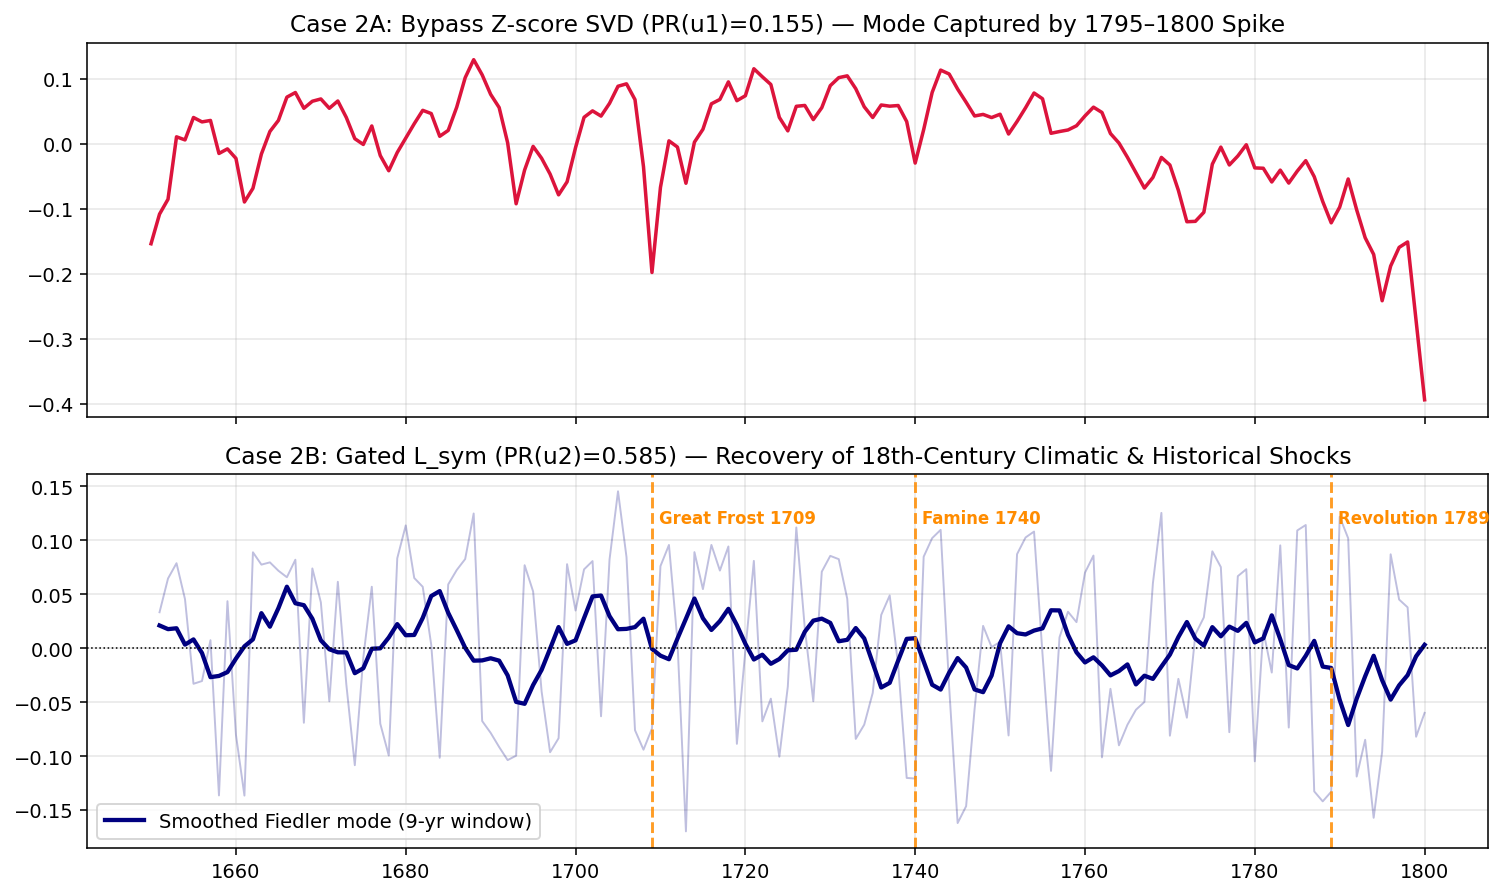

In [ ]:
archives = [
    f for f in os.listdir(".") if "ipvxmw" in f.lower() or f.endswith(".zip")
]
if not archives:
  raise FileNotFoundError(
      "Please upload 'doi-10.34894-ipvxmw.zip' to the Colab Files panel!"
  )

arch_file = archives.pop(0)
extract_dir = "allen_unger_data"
if not os.path.exists(extract_dir):
  with zipfile.ZipFile(arch_file, "r") as z:
    z.extractall(extract_dir)

wheat_files = sorted(glob.glob(f"{extract_dir}/**/*_Wheat.csv", recursive=True))
wheat_series = {}
for path in wheat_files:
  try:
    df_c = pd.read_csv(path, low_memory=False)
    yr_col = next(c for c in df_c.columns if "year" in str(c).lower())
    num_cols = [
        c
        for c in df_c.select_dtypes(include=[np.number]).columns
        if c != yr_col
    ]
    silver_cols = [
        c
        for c in num_cols
        if "silver" in str(c).lower() or "gram" in str(c).lower()
    ]
    val_col = silver_cols.pop(0) if silver_cols else num_cols[-1]
    city = os.path.basename(path).replace("_Wheat.csv", "")
    s = df_c.groupby(yr_col)[val_col].mean().dropna()
    if len(s) >= 50:
      wheat_series[city] = s
  except Exception:
    pass

df_w_all = pd.DataFrame(wheat_series).sort_index()
df_sub = df_w_all.loc[1650:1800]
valid_cities = df_sub.columns[df_sub.notna().mean() >= 0.85]
df_clean = df_sub[valid_cities].interpolate(method="linear").dropna()

cities_w = df_clean.columns.tolist()
X_w = df_clean.values.astype(float)
yrs_w = df_clean.index.values

res1_w = run_first_echelon_bypass(X_w, cities_w)
X_diff_w = np.diff(np.log(np.maximum(X_w, 1e-6)), axis=0)
X_diff_wz = (X_diff_w - X_diff_w.mean(axis=0)) / X_diff_w.std(axis=0)
_, _, evecs_w, gap_w = build_lsym_and_fiedler(X_diff_wz, k_nn=8)
u2_w = evecs_w[:, 1]
pr_u2_w = participation_ratio(u2_w)

print(
    f"=== CASE 2: ALLEN-UNGER WHEAT 1650–1800 ({len(yrs_w)} years x"
    f" {len(cities_w)} markets) ==="
)
print(
    f"Bypass: PR(u1) = {res1_w['pr_u1']:.3f} | PR(v1) = {res1_w['pr_v1']:.3f}"
    f" | Top share: {res1_w['top_label']} ({res1_w['top_share']:.1%})"
)
print(
    f"Gated (L_sym): PR(u2) = {pr_u2_w:.3f}"
    f" ({pr_u2_w / res1_w['pr_u1']:.1f}x increase in temporal uniformity)"
)

# Plot and save Case 2 figure
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
ax1.plot(yrs_w, res1_w["U"][:, 0], color="crimson", lw=1.8)
ax1.set_title(
    f"Case 2A: Bypass Z-score SVD (PR(u1)={res1_w['pr_u1']:.3f}) — Mode"
    " Captured by 1795–1800 Spike"
)
ax1.grid(True, alpha=0.3)

u2_w_smooth = np.convolve(u2_w, np.ones(9) / 9, mode="same")
ax2.plot(yrs_w[1:], u2_w, color="navy", alpha=0.25, lw=1)
ax2.plot(
    yrs_w[1:],
    u2_w_smooth,
    color="navy",
    lw=2.2,
    label="Smoothed Fiedler mode (9-yr window)",
)
ax2.axhline(0, color="black", ls=":", lw=0.8)
ymin, ymax = ax2.get_ylim()
for yr, lbl in [
    (1709, "Great Frost 1709"),
    (1740, "Famine 1740"),
    (1789, "Revolution 1789"),
]:
  ax2.axvline(yr, color="darkorange", ls="--", alpha=0.85)
  ax2.text(
      yr + 0.8,
      ymax * 0.72,
      lbl,
      color="darkorange",
      fontsize=8.5,
      fontweight="bold",
  )
ax2.set_title(
    f"Case 2B: Gated L_sym (PR(u2)={pr_u2_w:.3f}) — Recovery of 18th-Century"
    " Climatic & Historical Shocks"
)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figures/case2_allen_unger_wheat_1650_1800.png")
plt.show()


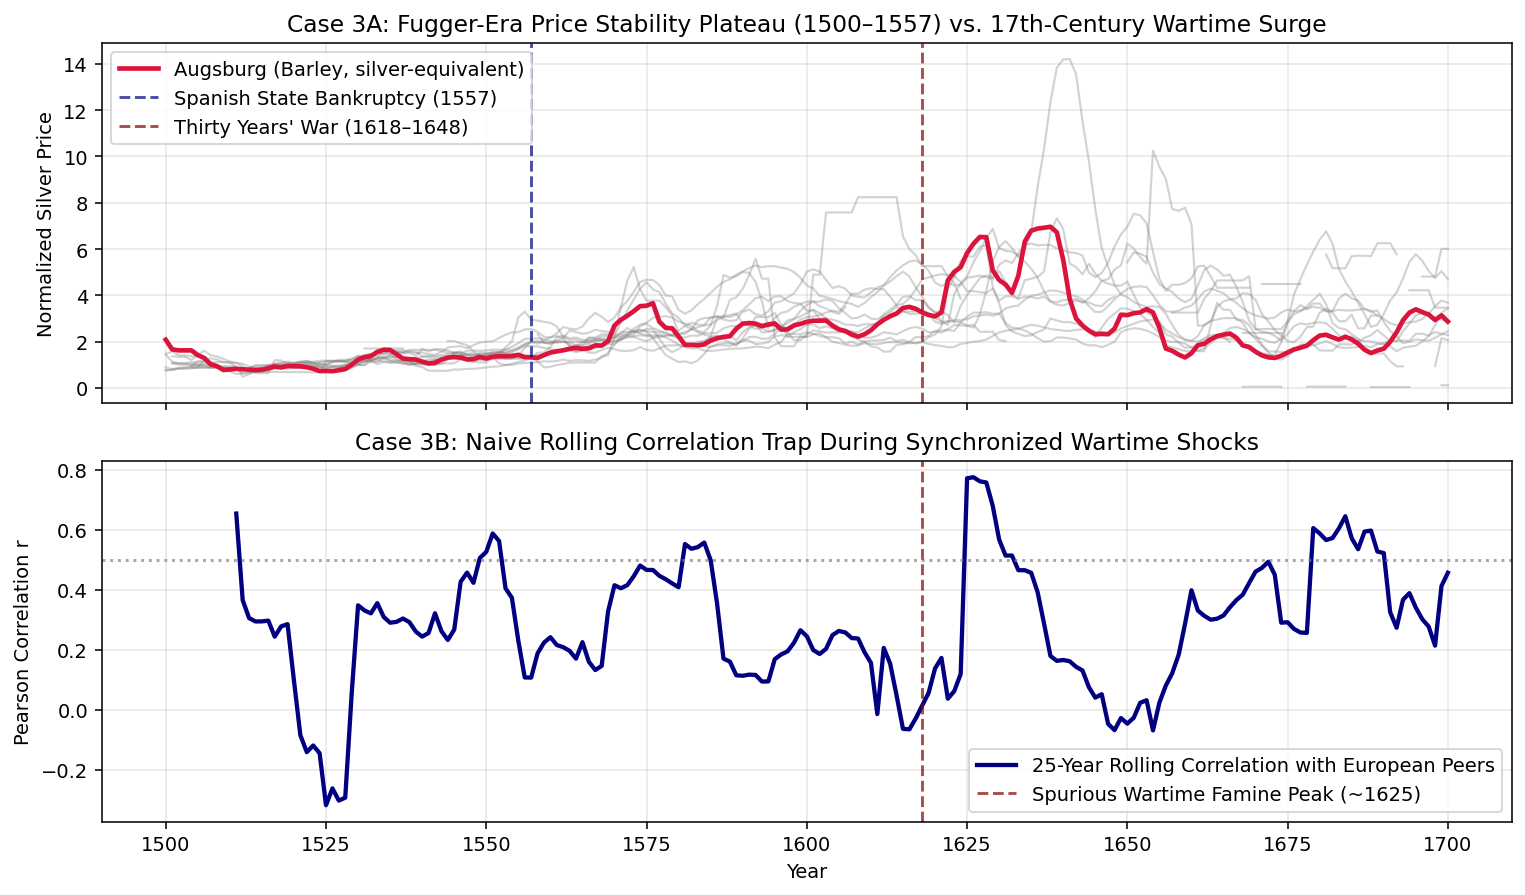

In [ ]:
barley_files = sorted(
    glob.glob(f"{extract_dir}/**/*_Barley.csv", recursive=True)
)
series_barley = {}
for path in barley_files:
  try:
    df_c = pd.read_csv(path, low_memory=False)
    yr_col = next(c for c in df_c.columns if "year" in str(c).lower())
    num_cols = [
        c
        for c in df_c.select_dtypes(include=[np.number]).columns
        if c != yr_col
    ]
    silver_cols = [
        c
        for c in num_cols
        if "silver" in str(c).lower() or "gram" in str(c).lower()
    ]
    val_col = silver_cols.pop(0) if silver_cols else num_cols[-1]
    city = os.path.basename(path).replace("_Barley.csv", "")
    s = df_c.groupby(yr_col)[val_col].mean().dropna()
    if s.index.min() <= 1525 and s.index.max() >= 1660:
      series_barley[city] = s
  except Exception:
    pass

df_b = pd.DataFrame(series_barley).loc[1500:1700]
other_cities = [c for c in df_b.columns if c != "Augsburg"]
eu_mean = df_b[other_cities].mean(axis=1)
rolling_corr = df_b["Augsburg"].rolling(25, min_periods=10).corr(eu_mean)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
df_norm = df_b / df_b.loc[1500:1530].mean()
for col in other_cities:
  ax1.plot(
      df_norm.index,
      df_norm[col].rolling(7, min_periods=1).mean(),
      color="gray",
      alpha=0.35,
      lw=1.1,
  )
ax1.plot(
    df_norm.index,
    df_norm["Augsburg"].rolling(7, min_periods=1).mean(),
    color="crimson",
    lw=2.4,
    label="Augsburg (Barley, silver-equivalent)",
)
ax1.axvline(
    1557, color="navy", ls="--", alpha=0.7, label="Spanish State Bankruptcy (1557)"
)
ax1.axvline(
    1618,
    color="darkred",
    ls="--",
    alpha=0.7,
    label="Thirty Years' War (1618–1648)",
)
ax1.set_title(
    "Case 3A: Fugger-Era Price Stability Plateau (1500–1557) vs. 17th-Century"
    " Wartime Surge"
)
ax1.set_ylabel("Normalized Silver Price")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(
    rolling_corr.index,
    rolling_corr,
    color="navy",
    lw=2.2,
    label="25-Year Rolling Correlation with European Peers",
)
ax2.axhline(0.5, color="gray", ls=":", alpha=0.7)
ax2.axvline(
    1618,
    color="darkred",
    ls="--",
    alpha=0.7,
    label="Spurious Wartime Famine Peak (~1625)",
)
ax2.set_title(
    "Case 3B: Naive Rolling Correlation Trap During Synchronized Wartime Shocks"
)
ax2.set_ylabel("Pearson Correlation r")
ax2.set_xlabel("Year")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figures/case3_augsburg_1500_1700.png")
plt.show()


In [ ]:
summary_df = pd.DataFrame([
    {
        "Benchmark": "Maddison 1820–1950 (GDP per capita)",
        "Dimensions (N x P)": f"{len(yrs_ind)} x {len(countries_ind)}",
        "Mode 1 Energy": f"{res1_ind['energy_1']:.1%}",
        "PR(u1) Temporal": round(res1_ind["pr_u1"], 3),
        "PR(v1) Spatial": round(res1_ind["pr_v1"], 3),
        "PR(u2) L_sym": round(participation_ratio(u2_ind), 3),
        "Primary Audit Diagnosis": (
            "Secular trend masking + spurious 1891 shift driven by Peru"
            " (LOO p=0.65)"
        ),
    },
    {
        "Benchmark": "Allen–Unger 1650–1800 (Wheat prices)",
        "Dimensions (N x P)": f"{len(yrs_w)} x {len(cities_w)}",
        "Mode 1 Energy": f"{res1_w['energy_1']:.1%}",
        "PR(u1) Temporal": round(res1_w["pr_u1"], 3),
        "PR(v1) Spatial": round(res1_w["pr_v1"], 3),
        "PR(u2) L_sym": round(pr_u2_w, 3),
        "Primary Audit Diagnosis": (
            "Mode capture by 1795–1800 spike + nested regional duplicates"
            " (England/Tuscany)"
        ),
    },
])

print("\n=== SUMMARY TABLE OF SPECTRAL AUDIT RESULTS ===")
display(summary_df)
summary_df.to_csv("figures/audit_summary_table.csv", index=False)

with zipfile.ZipFile("results_bundle.zip", "w") as zout:
  for fname in glob.glob("figures/*"):
    zout.write(fname)

print(
    "\nAll figures and summary table packaged into 'results_bundle.zip' — ready"
    " for GitHub release!"
)



=== SUMMARY TABLE OF SPECTRAL AUDIT RESULTS ===


,Benchmark,Dimensions (N x P),Mode 1 Energy,PR(u1) Temporal,PR(v1) Spatial,PR(u2) L_sym,Primary Audit Diagnosis
0,Maddison 1820–1950 (GDP per capita),131 x 12,89.6%,0.485,0.998,0.348,Secular trend masking + spurious 1891 shift dr...
1,Allen–Unger 1650–1800 (Wheat prices),151 x 25,44.7%,0.155,0.768,0.585,Mode capture by 1795–1800 spike + nested regio...



All figures and summary table packaged into 'results_bundle.zip' — ready for GitHub release!
